In [3]:
import sklearn
import pandas as pd
from sklearn.cross_decomposition import PLSRegression
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import numpy as np

from sklearn.preprocessing import scale 
from sklearn import model_selection
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.cross_decomposition import PLSRegression, PLSSVD

In [4]:
den_df = pd.read_csv('../../data/processed/radial_density_maps/prop_adair_densities.csv')
den_df

,Unnamed: 0,sys_id,ang45_ang,ang45_n,peak_ang,peak_n,peak45_ang,peak45_n,D.1,D.2,...,D.2691,D.2692,D.2693,D.2694,D.2695,D.2696,D.2697,D.2698,D.2699,D.2700
0,vec,17E_02,43.347000,259.103289,29.130000,305.667697,57.513000,300.177596,0.672269,0.638655,...,0.0,0.000000,0.0,0.0,0.189201,0.188789,0.0,0.100629,0.258354,0.340771
1,vec.1,17W_02,44.751000,437.789027,71.653000,504.605035,71.653000,504.605035,0.697479,0.655462,...,0.0,0.258343,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
2,vec.2,17E_03,44.132333,262.457203,27.658000,423.397728,66.342667,282.445304,0.714286,0.680672,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,vec.3,17W_03,44.945000,491.944857,53.902667,601.084565,53.902667,601.084565,0.672269,0.638655,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,vec.4,17E_04,44.223000,506.976605,45.577000,733.567235,45.577000,733.567235,0.663866,0.630252,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.234277,0.645436,0.168808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,vec.138,17E_71,44.535500,447.151346,77.682333,590.424362,77.682333,590.424362,0.647059,0.621849,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
132,vec.139,17W_71,44.912000,211.782153,32.206000,247.184740,51.004000,217.825303,0.655462,0.638655,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
133,vec.140,17E_72,44.572000,251.095235,72.784000,560.131035,72.784000,560.131035,0.647059,0.621849,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
134,vec.142,17E_73,44.910333,747.815255,31.596667,903.528827,51.998000,795.892234,0.731092,0.705882,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000


In [17]:
pls_peak = PLSRegression(n_components=50, scale=True)
X
# x_scaler = StandardScaler(copy=True, with_mean=True, with_std=True)
# X_scaled, Y_scaled = scaler.fit(X, Y)

,D.1,D.2,D.3,D.4,D.5,D.6,D.7,D.8,D.9,D.10,...,D.2691,D.2692,D.2693,D.2694,D.2695,D.2696,D.2697,D.2698,D.2699,D.2700
0,0.672269,0.638655,0.675000,0.661017,0.663866,0.663793,0.666667,0.689655,0.690909,0.684685,...,0.0,0.000000,0.0,0.0,0.189201,0.188789,0.0,0.100629,0.258354,0.340771
1,0.697479,0.655462,0.691667,0.661017,0.680672,0.681034,0.675214,0.681034,0.681818,0.666667,...,0.0,0.258343,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
2,0.714286,0.680672,0.716667,0.711864,0.705882,0.706897,0.700855,0.698276,0.700000,0.684685,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,0.672269,0.638655,0.666667,0.644068,0.638655,0.637931,0.632479,0.646552,0.636364,0.630631,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,0.663866,0.630252,0.650000,0.627119,0.638655,0.646552,0.623932,0.646552,0.654545,0.639640,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.234277,0.645436,0.168808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,0.647059,0.621849,0.641667,0.627119,0.638655,0.629310,0.623932,0.663793,0.654545,0.639640,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
132,0.655462,0.638655,0.666667,0.644068,0.655462,0.655172,0.641026,0.646552,0.654545,0.648649,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
133,0.647059,0.621849,0.641667,0.618644,0.621849,0.612069,0.606838,0.620690,0.627273,0.630631,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
134,0.731092,0.705882,0.725000,0.720339,0.731092,0.715517,0.717949,0.715517,0.718182,0.702703,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000


In [6]:
Y = den_df['peak_n'].values
Y

X = den_df.iloc[:,8:]
X

,D.1,D.2,D.3,D.4,D.5,D.6,D.7,D.8,D.9,D.10,...,D.2691,D.2692,D.2693,D.2694,D.2695,D.2696,D.2697,D.2698,D.2699,D.2700
0,0.672269,0.638655,0.675000,0.661017,0.663866,0.663793,0.666667,0.689655,0.690909,0.684685,...,0.0,0.000000,0.0,0.0,0.189201,0.188789,0.0,0.100629,0.258354,0.340771
1,0.697479,0.655462,0.691667,0.661017,0.680672,0.681034,0.675214,0.681034,0.681818,0.666667,...,0.0,0.258343,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
2,0.714286,0.680672,0.716667,0.711864,0.705882,0.706897,0.700855,0.698276,0.700000,0.684685,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,0.672269,0.638655,0.666667,0.644068,0.638655,0.637931,0.632479,0.646552,0.636364,0.630631,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,0.663866,0.630252,0.650000,0.627119,0.638655,0.646552,0.623932,0.646552,0.654545,0.639640,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.234277,0.645436,0.168808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,0.647059,0.621849,0.641667,0.627119,0.638655,0.629310,0.623932,0.663793,0.654545,0.639640,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
132,0.655462,0.638655,0.666667,0.644068,0.655462,0.655172,0.641026,0.646552,0.654545,0.648649,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
133,0.647059,0.621849,0.641667,0.618644,0.621849,0.612069,0.606838,0.620690,0.627273,0.630631,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
134,0.731092,0.705882,0.725000,0.720339,0.731092,0.715517,0.717949,0.715517,0.718182,0.702703,...,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000


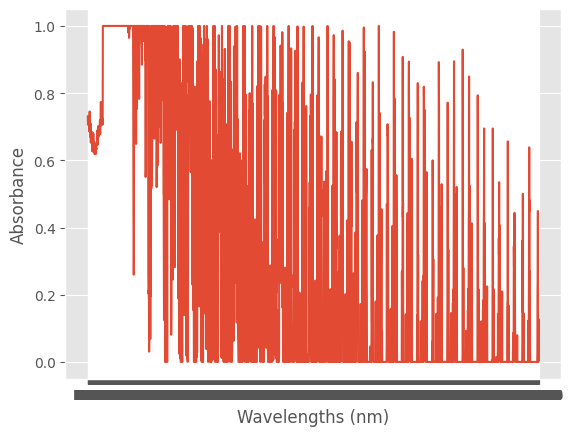

In [7]:
with plt.style.context('ggplot'):
    plt.plot(X.loc[100].T)
    plt.xlabel("Wavelengths (nm)")
    plt.ylabel("Absorbance")
    plt.show()
    plt.close()

In [8]:
X2 = savgol_filter(X, 17, polyorder=2, deriv=2)
X2 = savgol_filter(X, 17, polyorder=2, deriv=2)

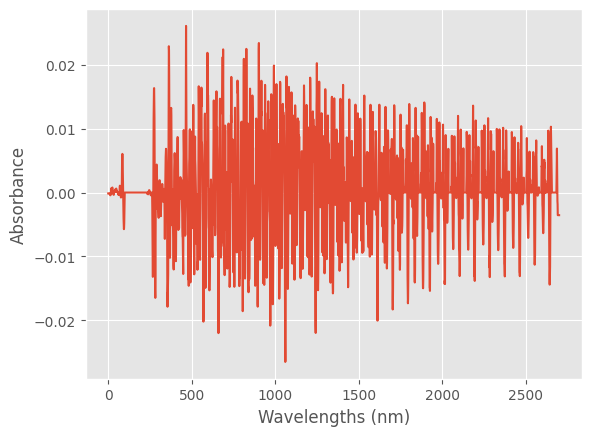

In [9]:
with plt.style.context('ggplot'):
    plt.plot(pd.DataFrame(X2).loc[100].T)
    plt.xlabel("Wavelengths (nm)")
    plt.ylabel("Absorbance")
    plt.show()
    plt.close()

In [10]:
pls_peak.fit(X2, Y)

PLSRegression(n_components=50)

In [11]:
pls_peak.y_weights_



array([[-8.74315704e-02,  6.90653591e-02,  4.22679218e-02,
        -3.56359551e-02, -2.56121210e-02,  2.72044591e-02,
        -2.11313370e-02,  2.29897797e-02,  1.34315631e-02,
         1.12334786e-02,  9.68330082e-03, -1.13771290e-02,
         4.51112239e-03,  6.46831350e-03,  7.29271354e-03,
         4.89756263e-03, -3.59805205e-03,  3.29323661e-03,
         1.84703681e-03,  1.61551107e-03, -1.70715098e-03,
        -8.43385693e-04,  8.15399853e-04, -7.99051360e-04,
        -5.12943168e-04, -3.81346265e-04,  2.64692629e-04,
        -2.31289399e-04,  1.98581740e-04,  1.34369047e-04,
        -1.25358847e-04,  6.91189982e-05, -6.39006096e-05,
         5.11257886e-05,  2.77878844e-05, -2.75477259e-05,
        -1.98163004e-05,  1.16986104e-05, -7.84058608e-06,
        -5.42129864e-06,  4.11267441e-06, -3.19992187e-06,
         2.59975469e-06,  1.58856286e-06,  9.65597304e-07,
        -7.81319561e-07, -5.57366880e-07,  3.70693598e-07,
        -2.28254041e-07, -1.77266996e-07]])

In [12]:
#Partial Least Squares
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(X2, Y, test_size = 0.20, random_state = 5)

# 10-fold CV, with shuffle
ten_fold = model_selection.KFold(n_splits=10, shuffle=True, random_state=1)

mse = []

for i in np.arange(1, 30):
    pls = PLSRegression(n_components=i)
    score = model_selection.cross_val_score(pls, scale(X_train), Y_train, cv=ten_fold, scoring='neg_root_mean_squared_error').mean()
    mse.append(-score)
# Plot results
plt.plot(np.arange(1, 30), np.array(mse), '-v')
plt.xlabel('No. of PLS Components in Regression')
plt.ylabel('MSE')
plt.title('Model MSE as No. of PLS Components Change')
plt.xlim(xmin=-1)

(-1.0, 30.4)

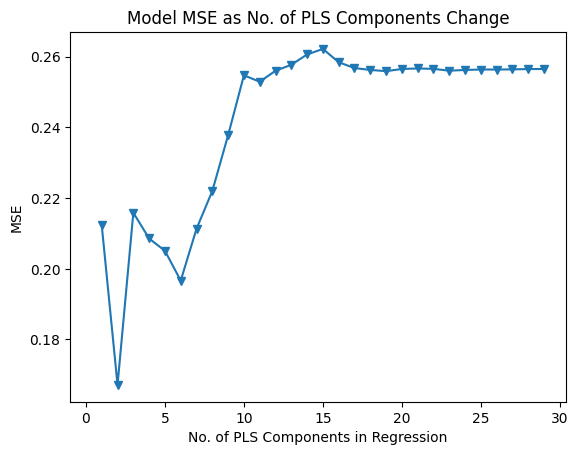

In [57]:
plt.show()

In [18]:
pls_peak.fit(X, Y)

PLSRegression(n_components=50)

In [28]:
pls_peak.coef_.flatten()

array([-3.16363994, -3.11051516, -3.90785083, ...,  1.08546799,
        2.19477873,  1.16114306])

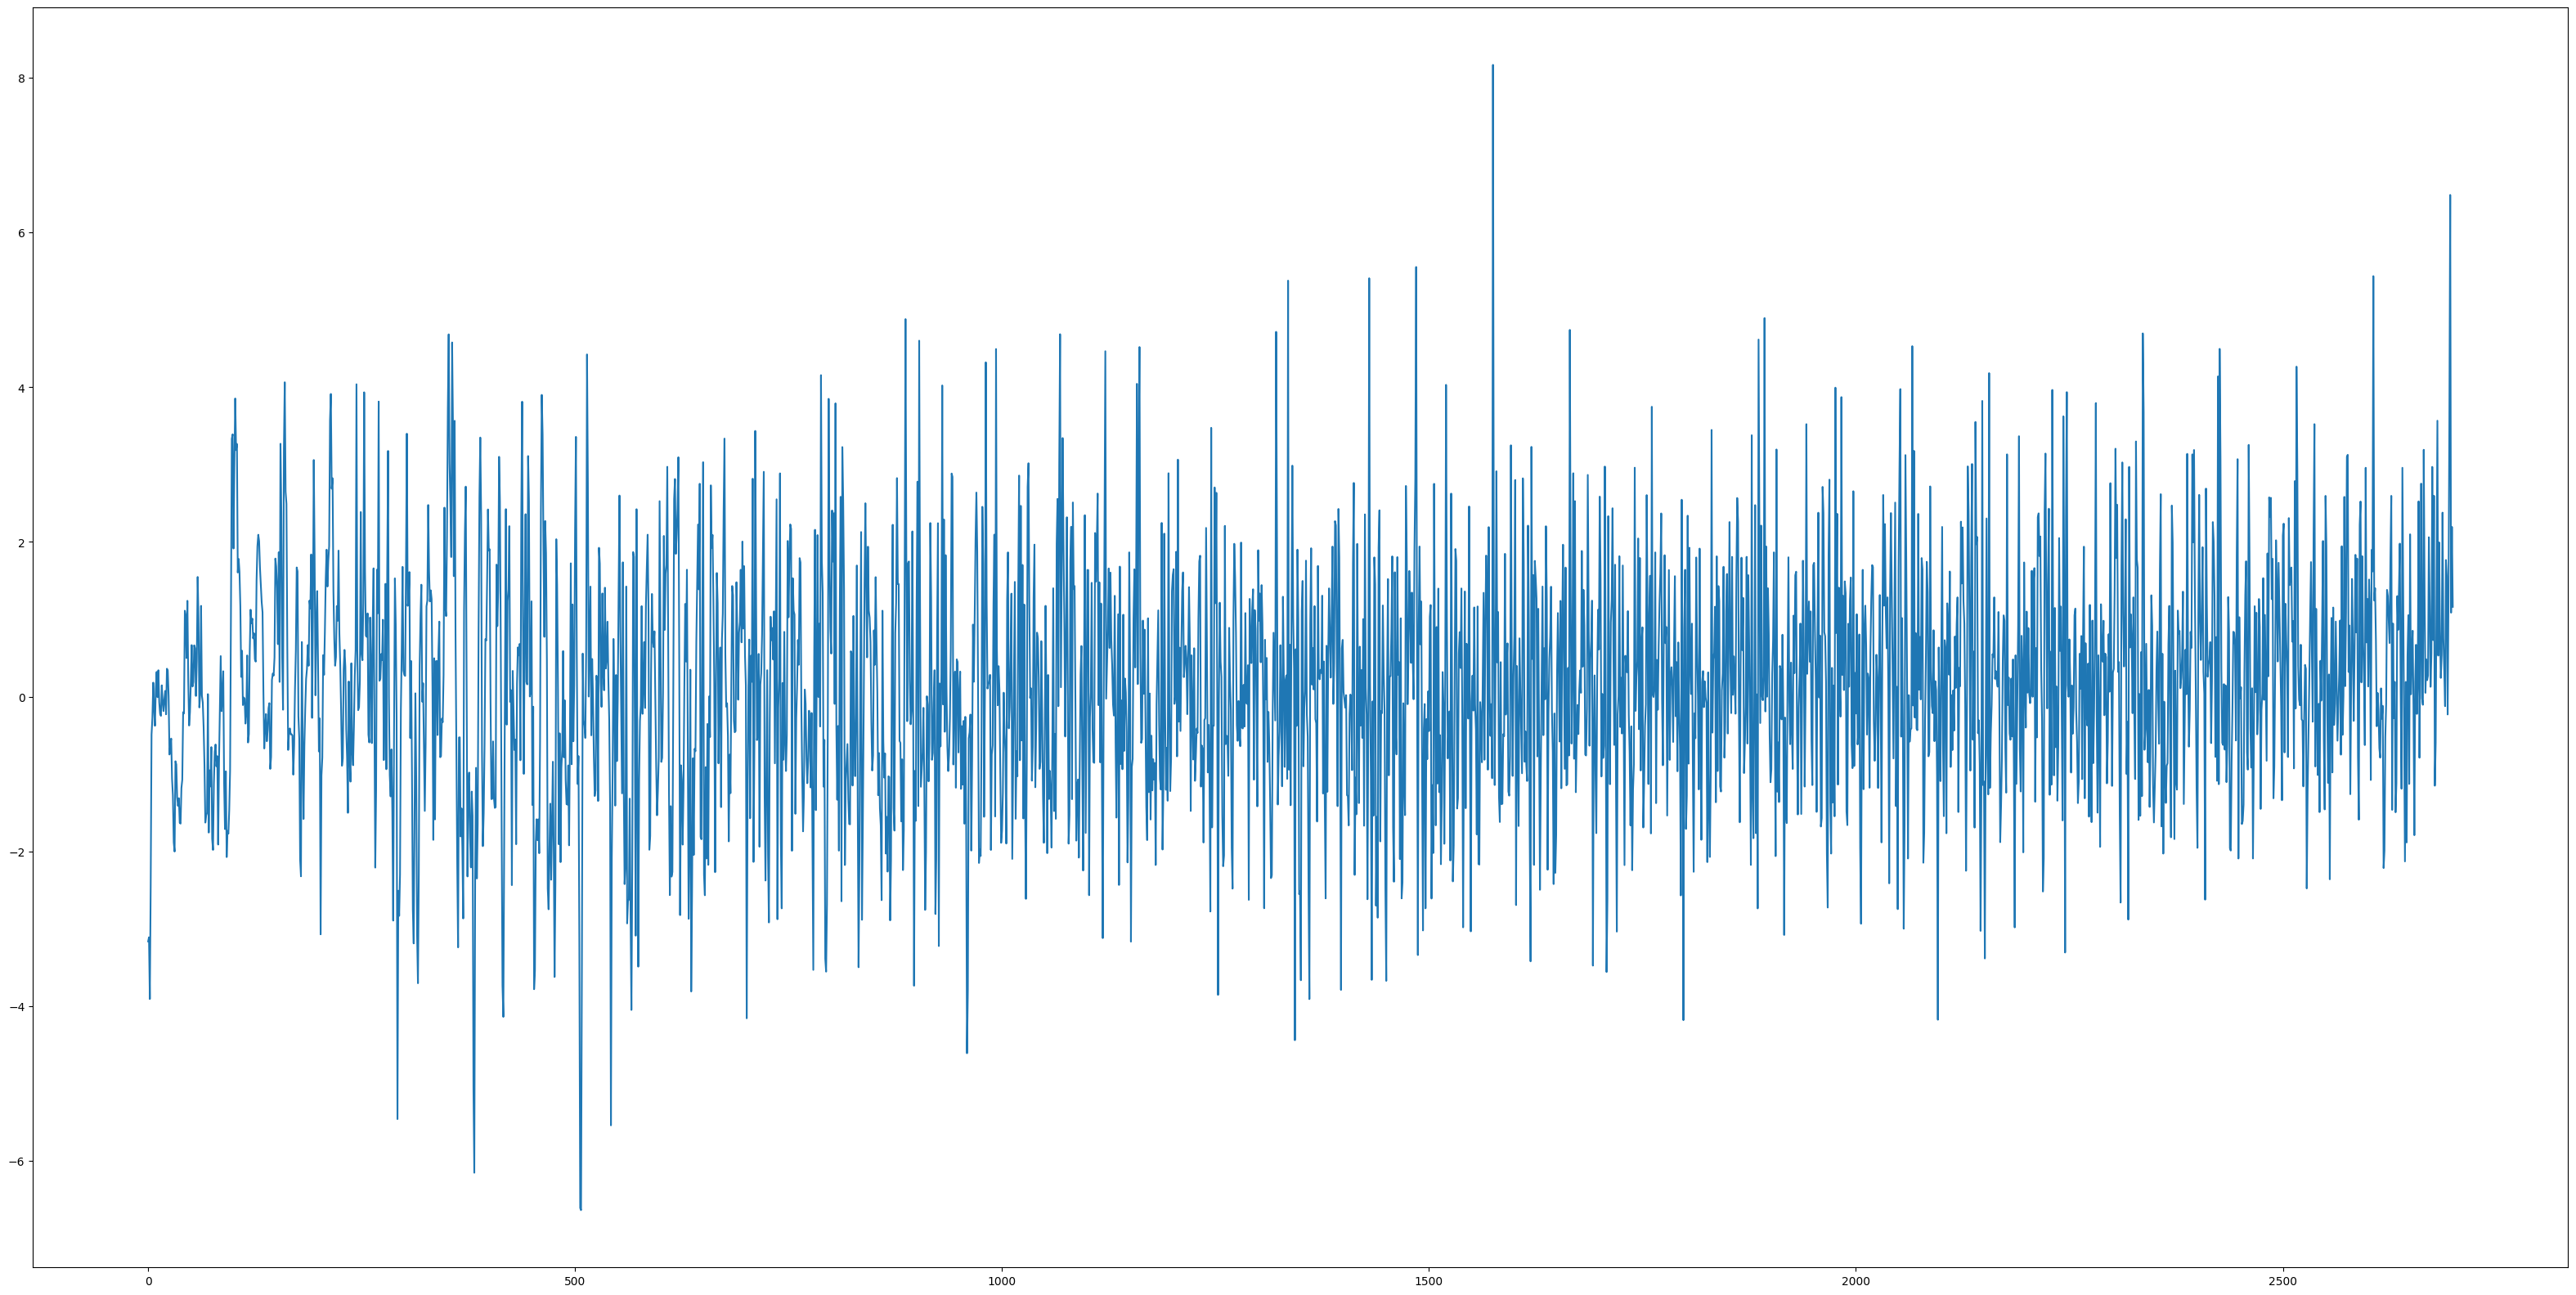

In [37]:
plt.close()
plt.figure(figsize=(40, 20))
plt.plot([i for i in range(2700)], pls_peak.coef_.flatten())
plt.show()


In [38]:
!pip install u8darts

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 kB 1.0 MB/s eta 0:00:001.1 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.5/160.5 kB 3.8 MB/s eta 0:00:004.1 MB/s eta 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 10.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 18.2 MB/s eta 0:00:00
  Using cached typing_extensions-4.9.0-py3-none-any.whl.metadata (3.0 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 15.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.2/144.2 kB 12.1 MB/s eta 0:00:00
  Using cached fsspec-2023.12.2-py3-none-any.whl.metadata (6.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.3/135.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 817.8/817.8 kB 8.4 MB/s eta 0:00:00 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.8/869.8 kB 10.5 MB/s et